In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle

sys.path.insert(0, "./cellular_cycle")
sys.path.insert(0, "./figures")

import fracprolif as fp
from cell_cycle_death_model import model
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from model_fxns import *
from Cell_Population_Simulation import Cell_Population_Simulation
from SMs_G1s_IMTs_extraction import SMs_G1s_IMTs_extraction
from call_cell_events import call_events #
from retrieve_cellState import retrieve_cellState #

In [2]:
# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

SAVE_CELL_DATA = False

In [3]:
# import pysb sampled parameters
sampled_parameter_names = np.loadtxt('model_data/sampled_parameter_names.txt', dtype=str)

In [4]:
# Importing the parameters:
new_param = pd.read_csv('model_data/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

In [42]:
with open('fit_data/pso/frac_prolif_parameters_pso.pkl', 'rb') as f:
    frac_prolif_parameters_pso = pickle.load(f)
new_param_pso_sort = frac_prolif_parameters_pso.sort_values([('cost', 'total cost likelihood')])
frac_prolif_parameters_pso[('cost', 'custom cost populations')] = frac_prolif_parameters_pso[('cost', 'cost population dynamics 0.6 kPa DMSO')] + frac_prolif_parameters_pso[('cost', 'cost population dynamics 0.6 kPa erlotinib')] + frac_prolif_parameters_pso[('cost', 'cost population dynamics 4 kPa DMSO')] + frac_prolif_parameters_pso[('cost', 'cost population dynamics 4 kPa erlotinib')] + frac_prolif_parameters_pso[('cost', 'cost 55 kPa erlotinib')] + frac_prolif_parameters_pso[('cost', 'cost 55 kPa DMSO')]
# frac_prolif_parameters_pso[('cost', 'custom cost populations')] = frac_prolif_parameters_pso[('cost', 'cost population dynamics 0.6 kPa DMSO')] + frac_prolif_parameters_pso[('cost', 'cost population dynamics 4 kPa DMSO')] + frac_prolif_parameters_pso[('cost', 'cost population dynamics 4 kPa erlotinib')] + frac_prolif_parameters_pso[('cost', 'cost 55 kPa erlotinib')]

new_param_pso_sort = frac_prolif_parameters_pso.sort_values(by=[('cost', 'custom cost populations')])
# new_param_pso_sort = new_param_pso_sort.dropna()
new_params = new_param_pso_sort['model parameters']
# Importing the parameters:
ii = 0
for key in new_params.keys():
    try:
        if model.parameters[key].value != new_params[key].iloc[ii]:
            model.parameters[key].value = new_params[key].iloc[ii]
    except:
        print(key)
model.parameters['omega'].value = 200

In [47]:
new_param_pso_sort

pso           fractional proliferation model                  \
   chain iteration                 a 0.6 kPa DMSO mu 0.6 kPa DMSO   
0      8        45                       0.000000       19.719114   
0      8        54                       0.000000       21.845453   
0     30        14                       0.000000       18.939253   
0      8        59                       0.000000       33.606644   
0     31        43                       0.000000       17.033387   
..   ...       ...                            ...             ...   
0     14        29                       0.010977       19.725314   
0      2        35                       0.018949       19.637748   
0      3        46                       0.013697       18.009089   
0      3        32                       0.010060       18.948334   
0     33        62                            NaN             NaN   

                                                                         \
   sigma 0.6 kPa DMSO lambda 0.6 kPa DMSO d 0.6 kPa DMSO q 0.6 kPa DMSO   
0            0.010000            0.038795       0.016855   5.849705e-04   
0            0.010000            0.025710       0.012999   0.000000e+00   
0            0.010000            0.044622       0.018383   1.712529e-03   
0           11.154864            0.020049       0.009371   0.000000e+00   
0            0.010000            0.038743       0.018143   2.123262e-03   
..                ...                 ...            ...            ...   
0            1.658037            0.211921       0.028748   2.386236e-04   
0            1.441140            0.207753       0.028742   3.276820e-18   
0            1.899194            0.091724       0.025114   2.511401e-43   
0            1.496340            0.069578       0.022070   2.206982e-43   
0                 NaN                 NaN            NaN            NaN   

                                             ...              cost  \
   a 0.6 kPa erlotinib mu 0.6 kPa erlotinib  ... cost 0.6 kPa DMSO   
0             0.000663            68.699732  ...          0.533292   
0             0.000690            36.689672  ...          0.415346   
0             0.000804            53.125479  ...          0.357043   
0             0.000000                  NaN  ...          0.722097   
0             0.000000            67.041144  ...          0.290800   
..                 ...                  ...  ...               ...   
0             0.017056                  NaN  ...          0.210286   
0             0.023396            24.808311  ...          0.231589   
0             0.020316                  NaN  ...          0.242185   
0             0.013613                  NaN  ...          0.288235   
0                  NaN                  NaN  ...               NaN   

                                                                               \
   cost 0.6 kPa erlotinib cost 0.6 kPa cost 55 kPa DMSO cost 55 kPa erlotinib   
0                0.460395     0.993687         0.106762              0.393726   
0                0.714806     1.130152         0.155787              0.382809   
0                0.632427     0.989469         0.275397              0.267034   
0                     NaN          NaN         0.093264              0.390748   
0                0.654172     0.944972         0.212785              0.294928   
..                    ...          ...              ...                   ...   
0                     NaN          NaN         0.226742              0.325498   
0                     NaN          NaN         0.320223              0.447868   
0                     NaN          NaN         0.153725              0.550744   
0                     NaN          NaN         0.222869              0.529285   
0                     NaN          NaN              NaN                   NaN   

                     umap                             pareto  \
   cost 55 kPa      dim 1     dim 2 cost 0.6 kPa cost 55 kPa   
0     0.500487  -0.140122 -8.808308   

In [45]:
# Save the DataFrame to a pickle file
new_param_pso_sort.to_pickle('fit_data/pso/frac_prolif_parameters_pso_sorted.pkl')

In [23]:
def change_params(param_num):
    for key in new_params.keys():
        try:
            if model.parameters[key].value != new_params[key].iloc[param_num]:
                model.parameters[key].value = new_params[key].iloc[param_num]
        except:
            print(key)

In [24]:
# Setting initial concentrations '/../model_data/initial_concentrations.csv'
initial_concentrations = pd.read_csv('model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

In [25]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv('model_data/ECM_conditions_2.csv')
ECM_conditions


,condition,stiffness,drug,species,value
0,55 kPa DMSO,55 kPa,DMSO,AKT,1.0
1,55 kPa DMSO,55 kPa,DMSO,ERK,1.0
2,55 kPa DMSO,55 kPa,DMSO,FAK,1.0
3,4 kPa DMSO,4 kPa,DMSO,AKT,1.0
4,4 kPa DMSO,4 kPa,DMSO,ERK,1.0
5,4 kPa DMSO,4 kPa,DMSO,FAK,0.6
6,0.6 kPa DMSO,0.6 kPa,DMSO,AKT,0.6
7,0.6 kPa DMSO,0.6 kPa,DMSO,ERK,1.0
8,0.6 kPa DMSO,0.6 kPa,DMSO,FAK,0.4
9,55 kPa erlotinib,55 kPa,erlotinib,AKT,0.6


In [26]:
init = 5
run_time = 120
observed_cells_time = 120
condition = "55 kPa erlotinib"
size = (7,3)

In [27]:
conditions = ['0.6 kPa erlotinib', '0.6 kPa DMSO', '4 kPa erlotinib', '4 kPa DMSO', '55 kPa erlotinib', '55 kPa DMSO']

0.6 kPa erlotinib
0.6 kPa DMSO
4 kPa erlotinib
4 kPa DMSO
55 kPa erlotinib
55 kPa DMSO
0.6 kPa erlotinib
0.6 kPa DMSO
4 kPa erlotinib
4 kPa DMSO
55 kPa erlotinib
55 kPa DMSO
0.6 kPa erlotinib
0.6 kPa DMSO
4 kPa erlotinib
4 kPa DMSO
55 kPa erlotinib
55 kPa DMSO
0.6 kPa erlotinib
0.6 kPa DMSO
4 kPa erlotinib
4 kPa DMSO
55 kPa erlotinib
55 kPa DMSO
0.6 kPa erlotinib
0.6 kPa DMSO
4 kPa erlotinib
4 kPa DMSO
55 kPa erlotinib
55 kPa DMSO
0.6 kPa erlotinib
0.6 kPa DMSO
4 kPa erlotinib
4 kPa DMSO
55 kPa erlotinib
55 kPa DMSO
0.6 kPa erlotinib
0.6 kPa DMSO
4 kPa erlotinib
4 kPa DMSO
55 kPa erlotinib
55 kPa DMSO
0.6 kPa erlotinib
0.6 kPa DMSO
4 kPa erlotinib
4 kPa DMSO
55 kPa erlotinib
55 kPa DMSO
0.6 kPa erlotinib
0.6 kPa DMSO
4 kPa erlotinib
4 kPa DMSO
55 kPa erlotinib
55 kPa DMSO
0.6 kPa erlotinib
0.6 kPa DMSO
4 kPa erlotinib
4 kPa DMSO
55 kPa erlotinib
55 kPa DMSO
0.6 kPa erlotinib
0.6 kPa DMSO
4 kPa erlotinib
4 kPa DMSO
55 kPa erlotinib
55 kPa DMSO


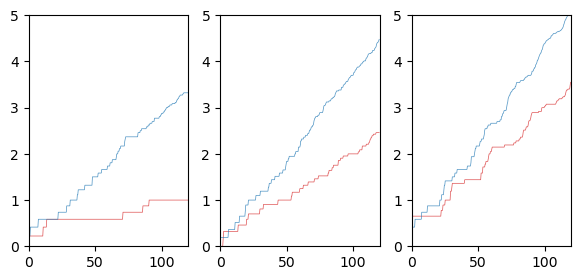

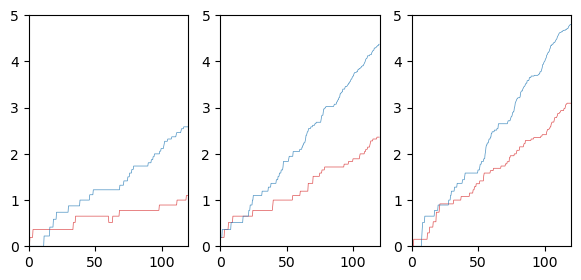

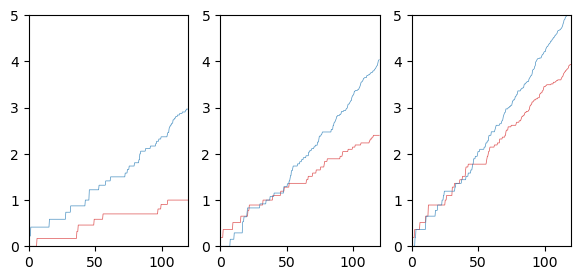

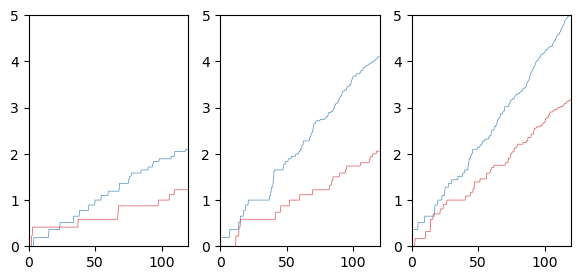

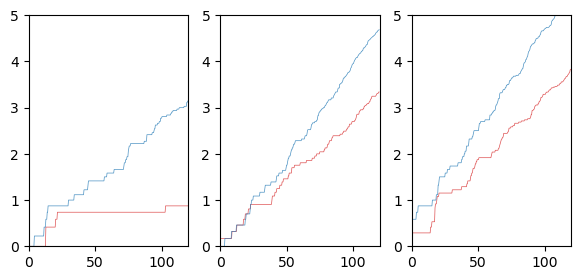

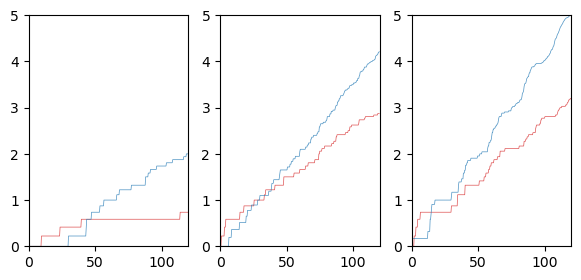

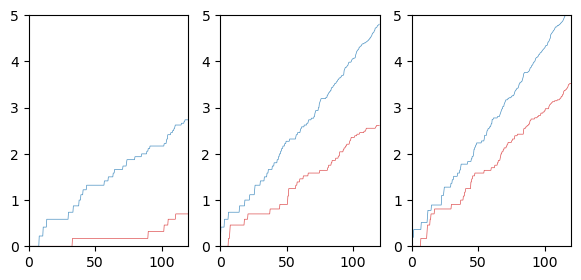

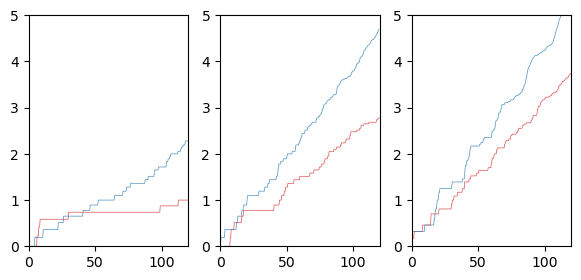

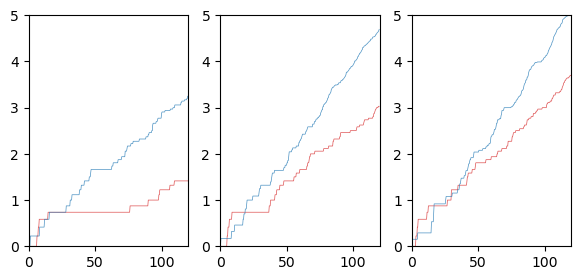

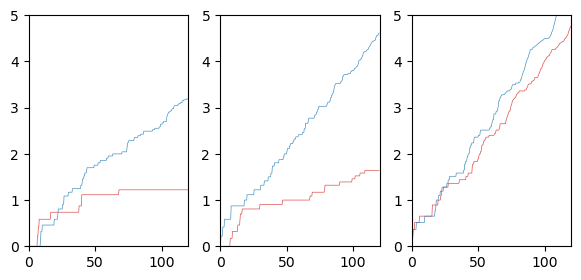

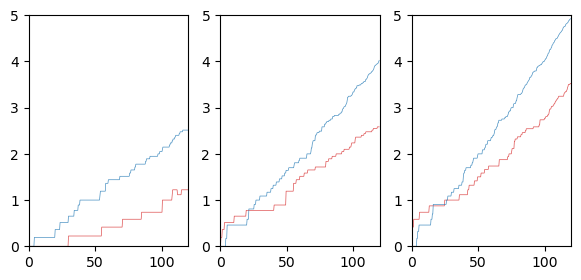

In [44]:
for num in range(11):
    change_params(num)
    
    fig, axes = plt.subplots(1, 3, figsize=size)
    
    for condition in conditions:
        for ii in range(1):
            init = 5
                
            (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
            
            if "0.6" in condition:
                n = 0
            elif "4" in condition:
                n = 1
            else:
                n = 2
            if 'DMSO' in condition:    
                add_plot(cell_count, run_time, fig, axes[n], title=condition, color='tab:blue')
            else:
                add_plot(cell_count, run_time, fig, axes[n], title=condition, color='tab:red')

            axes[n].set_xlim(0, 120)
            axes[n].set_ylim(0, 5)
        
    fig_path = Path(SAVE_DIR, f'PSO_pops_custom_{num}.svg')
    plt.savefig(fig_path, bbox_inches='tight')

0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa DMSO
0.6 kPa DMSO
0.6 kPa DMSO
4 kPa erlotinib
4 kPa erlotinib
4 kPa erlotinib
4 kPa DMSO
4 kPa DMSO
4 kPa DMSO
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa DMSO
55 kPa DMSO
55 kPa DMSO
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa DMSO
0.6 kPa DMSO
0.6 kPa DMSO
4 kPa erlotinib
4 kPa erlotinib
4 kPa erlotinib
4 kPa DMSO
4 kPa DMSO
4 kPa DMSO
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa DMSO
55 kPa DMSO
55 kPa DMSO
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa DMSO
0.6 kPa DMSO
0.6 kPa DMSO
4 kPa erlotinib
4 kPa erlotinib
4 kPa erlotinib
4 kPa DMSO
4 kPa DMSO
4 kPa DMSO
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa DMSO
55 kPa DMSO
55 kPa DMSO
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa DMSO
0.6 kPa DMSO
0.6 kPa DMSO
4 kPa erlotinib
4 kPa erlotinib
4 kPa erlotinib
4 kPa DMSO
4 kPa DMSO
4 kPa DMSO
55 kPa erlotinib
55 kPa erlotinib
55 kPa er

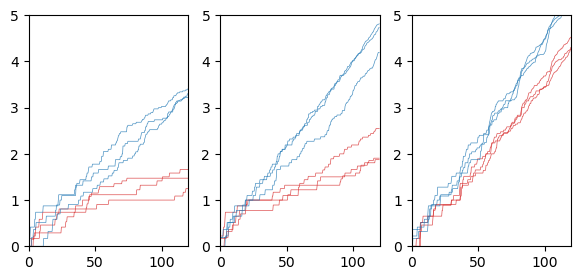

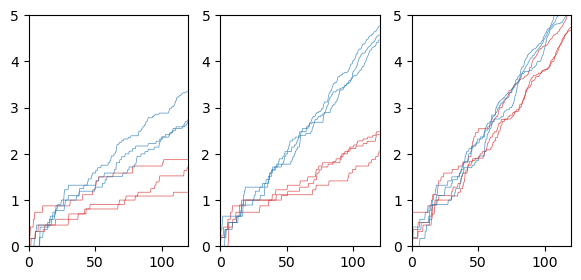

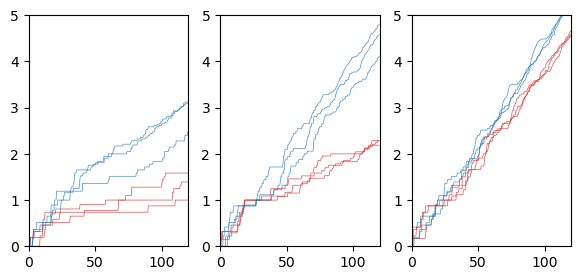

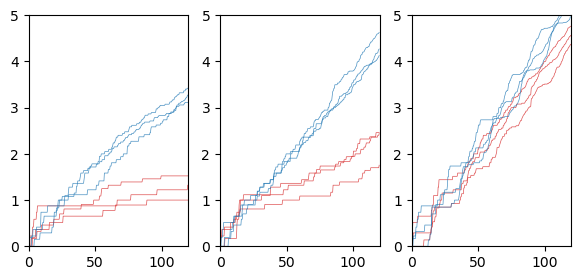

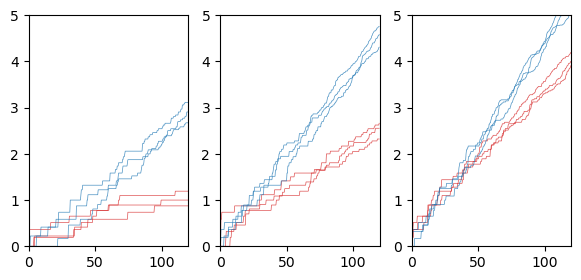

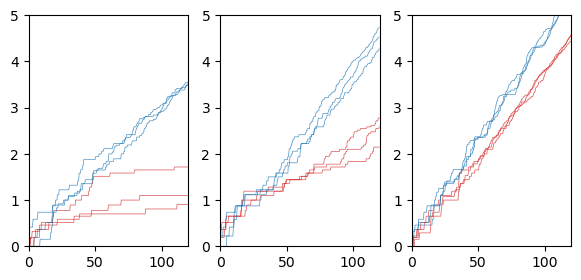

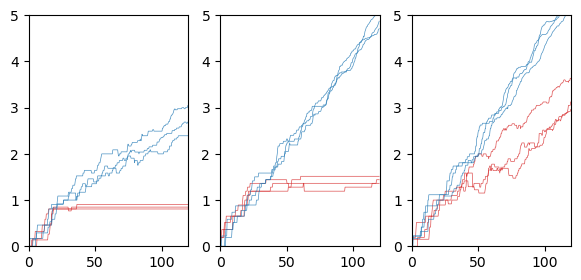

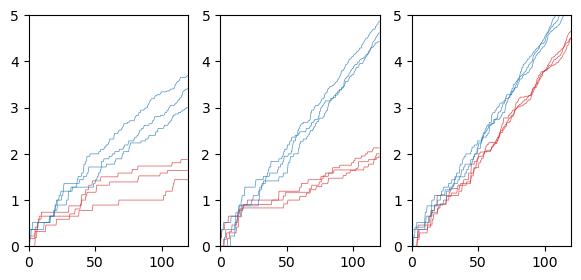

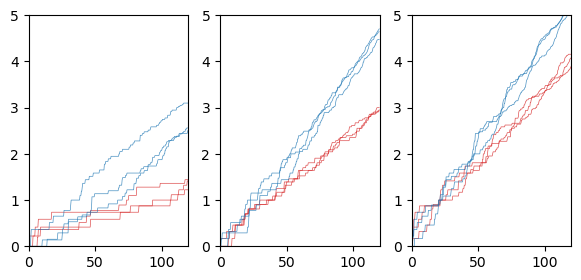

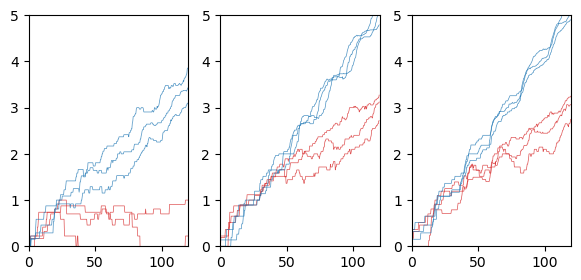

In [15]:
for num in range(2):
    change_params(num)
    
    fig, axes = plt.subplots(1, 3, figsize=size)
    
    for condition in conditions:
        for ii in range(3):
            init = 5
                
            (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
            
            if "0.6" in condition:
                n = 0
            elif "4" in condition:
                n = 1
            else:
                n = 2
            if 'DMSO' in condition:    
                add_plot(cell_count, run_time, fig, axes[n], title=condition, color='tab:blue')
            else:
                add_plot(cell_count, run_time, fig, axes[n], title=condition, color='tab:red')

            axes[n].set_xlim(0, 120)
            axes[n].set_ylim(0, 5)
        
    fig_path = Path(SAVE_DIR, f'PSO_pops_custom_{num}.svg')
    plt.savefig(fig_path, bbox_inches='tight')

0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa DMSO
0.6 kPa DMSO
0.6 kPa DMSO
4 kPa erlotinib
4 kPa erlotinib
4 kPa erlotinib
4 kPa DMSO
4 kPa DMSO
4 kPa DMSO
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa DMSO
55 kPa DMSO
55 kPa DMSO
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa DMSO
0.6 kPa DMSO
0.6 kPa DMSO
4 kPa erlotinib
4 kPa erlotinib
4 kPa erlotinib
4 kPa DMSO
4 kPa DMSO
4 kPa DMSO
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa DMSO
55 kPa DMSO
55 kPa DMSO


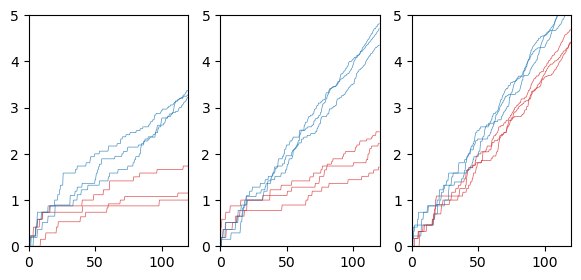

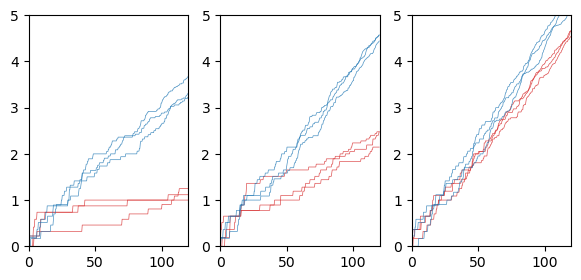

In [35]:
for num in range(2):
    change_params(num)
    
    fig, axes = plt.subplots(1, 3, figsize=size)
    
    for condition in conditions:
        for ii in range(3):
            init = 5
                
            (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
            
            if "0.6" in condition:
                n = 0
            elif "4" in condition:
                n = 1
            else:
                n = 2
            if 'DMSO' in condition:    
                add_plot(cell_count, run_time, fig, axes[n], title=condition, color='tab:blue')
            else:
                add_plot(cell_count, run_time, fig, axes[n], title=condition, color='tab:red')

            axes[n].set_xlim(0, 120)
            axes[n].set_ylim(0, 5)
        
    fig_path = Path(SAVE_DIR, f'PSO_pops_custom_{num}.svg')
    plt.savefig(fig_path, bbox_inches='tight')

0.6 kPa erlotinib
BAXm_0
BCL2_0
0.6 kPa DMSO
BAXm_0
BCL2_0
4 kPa erlotinib
BAXm_0
BCL2_0
4 kPa DMSO
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa DMSO
BAXm_0
BCL2_0


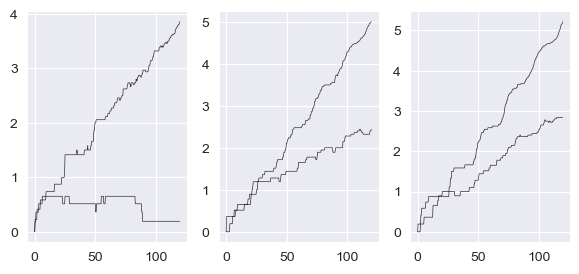

In [14]:
num = 0
change_params(num)

fig, axes = plt.subplots(1, 3, figsize=size)

for condition in conditions:
    init = 5
        
    (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
    
    if "0.6" in condition:
        n = 0
    elif "4" in condition:
        n = 1
    else:
        n = 2
        
    add_plot(cell_count, run_time, fig, axes[n], title=condition)
    
    
fig_path = Path(SAVE_DIR, f'PSO_pops_{num}.svg')
plt.savefig(fig_path, bbox_inches='tight')